In [2]:
"""

the aperature stuff is in here!!

"""

'\ncopied from full_image_extractions but for the larger set of implanted images \nwith the new CNN\n\ni make figures here but they are coppied and improved in plots_figures\n\n\nold nb goal: the goal of this notebook is to run cnn and get efficiencies\nand such from the folder of full_image_implants that i \njust made.\n\n'

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from astropy.io import fits
import scipy.ndimage as snm

In [2]:
from tqdm.auto import tqdm
import os
from pylab import cm
import matplotlib as mpl
import get_postage_stamps as gpsf
import pandas as pd

In [3]:
import plot_time_series as pts
import precision_recall as pr
import importlib

# importlib.reload(plot_time_series)
import gc  # garbage collector
import glob  # i don't know if there is a better way to do this but this was the

# internet's suggestion for searching with an incomplete path name
import review_findings_functions as rff

In [5]:
# some matplotlib defaults
plt.rcParams["figure.figsize"] = (10, 7)
plt.rcParams["image.interpolation"] = "nearest"
plt.rcParams["image.cmap"] = "gist_gray"

In [4]:
from scipy.signal import find_peaks
from scipy.optimize import curve_fit

In [ ]:
"""

HERE I AM GETTING THE APERATURE SIZE

"""

In [24]:
def gaussian(x, amp, cen, sigma):
    return amp * np.exp(-((x - cen) ** 2) / (2 * sigma**2))


def get_widths(fname, method=1500, plot=False):
    """'
    fname is the file name
    method is whether you want the average streak or a specific
    (keyword 'avg' for that)
    row on the streak - it defaults to row 1500
    plot is whether or not you plot it
    """
    hdul = fits.open(fname)
    # print(path)
    file1_array = hdul[1].data

    background = rff.get_image_background(file1_array)

    # subtracting background
    imagenobackground = file1_array - np.full(np.shape(file1_array), background)

    if method == "avg":
        x = np.linspace(
            0,
            len(np.average(imagenobackground, axis=0)) - 1,
            len(np.average(imagenobackground, axis=0)),
        )
        y = np.average(imagenobackground, axis=0)
    else:
        x = np.linspace(
            0,
            len(np.average(imagenobackground, axis=0)) - 1,
            len(np.average(imagenobackground, axis=0)),
        )
        y = imagenobackground[method, :]

    # Step 1: Find peaks
    peaks, _ = find_peaks(y, height=300)  # Adjust height threshold for your data

    # Step 2: Define Gaussian function

    # Initialize a list to store sigma values
    sigma_list = []

    # Step 3: Fit Gaussian to each peak and calculate sigma
    for peak in peaks:
        # Select a region around the peak for fitting
        left = max(0, peak - 20)
        right = min(len(x), peak + 20)
        x_fit = x[left:right]
        y_fit = y[left:right]

        # Initial guess for parameters: amplitude, center, and width
        p0 = [y[peak], x[peak], 1]

        # Use bounds to guide the fitting process
        bounds = (
            [0, x[peak] - 5, 0],
            [np.inf, x[peak] + 5, np.inf],
        )  # Constrain width and center

        try:
            # Increase maxfev to allow more function evaluations
            popt, _ = curve_fit(
                gaussian, x_fit, y_fit, p0=p0, bounds=bounds, maxfev=2000
            )

            # Extract fitted parameters
            amp, cen, sigma = popt
            # fwhm = 2.355 * sigma  # FWHM formula

            # Store FWHM in the list
            sigma_list.append(sigma)

            if plot == True:
                # # Plot the data and fitted Gaussian
                plt.plot(x, y, label="Data")
                plt.plot(
                    x_fit,
                    gaussian(x_fit, *popt),
                    label=f"Fitted peak at {cen:.2f} with FWHM={fwhm:.2f}",
                )
                plt.legend()

        except RuntimeError as e:
            print(f"Could not fit peak at x={x[peak]}: {e}")
    return sigma_list
    # Output the list of sigma values
    # print("FWHM values for detected peaks:", fwhm_list)


# plt.show()

In [13]:
path = "/lustre/lrspec/ZTF_data/science_extractions/to_extract/1020_minus_extras/"

In [14]:
files = [
    "ztf_20221020138241_000686_zi_c02_x_0017.fits.fz",
    "ztf_20221020154120_000640_zi_c05_x_0020.fits.fz",
    "ztf_20221020297847_000449_zr_c04_x_0005.fits.fz",
    "ztf_20221020154120_000640_zi_c05_x_0021.fits.fz",
    "ztf_20221020297847_000449_zr_c04_x_0006.fits.fz",
    "ztf_20221020154120_000640_zi_c05_x_0022.fits.fz",
    "ztf_20221020297847_000449_zr_c04_x_0007.fits.fz",
    "ztf_20221020154120_000640_zi_c05_x_0023.fits.fz",
    "ztf_20221020297847_000449_zr_c04_x_0008.fits.fz",
    "ztf_20221020154120_000640_zi_c05_x_0024.fits.fz",
    "ztf_20221020297847_000449_zr_c04_x_0009.fits.fz",
    "ztf_20221020154120_000640_zi_c05_x_0025.fits.fz",
    "ztf_20221020297847_000449_zr_c04_x_0010.fits.fz",
    "ztf_20221020154120_000640_zi_c05_x_0026.fits.fz",
    "ztf_20221020297847_000449_zr_c04_x_0011.fits.fz",
    "ztf_20221020154120_000640_zi_c05_x_0027.fits.fz",
    "ztf_20221020297847_000449_zr_c04_x_0012.fits.fz",
    "ztf_20221020154120_000640_zi_c05_x_0028.fits.fz",
    "ztf_20221020297847_000449_zr_c04_x_0013.fits.fz",
    "ztf_20221020154120_000640_zi_c05_x_0029.fits.fz",
    "ztf_20221020297847_000449_zr_c04_x_0014.fits.fz",
    "ztf_20221020154120_000640_zi_c06_x_0000.fits.fz",
    "ztf_20221020297847_000449_zr_c04_x_0015.fits.fz",
]

In [11]:
len(files)

23

In [28]:
sigmas = []
for file in files:
    fpath = path + file
    f_list = get_widths(fpath, method=1500)
    for el in f_list:
        sigmas.append(el)

In [26]:
len(sigmas)

102

Average:  0.9897492234359703


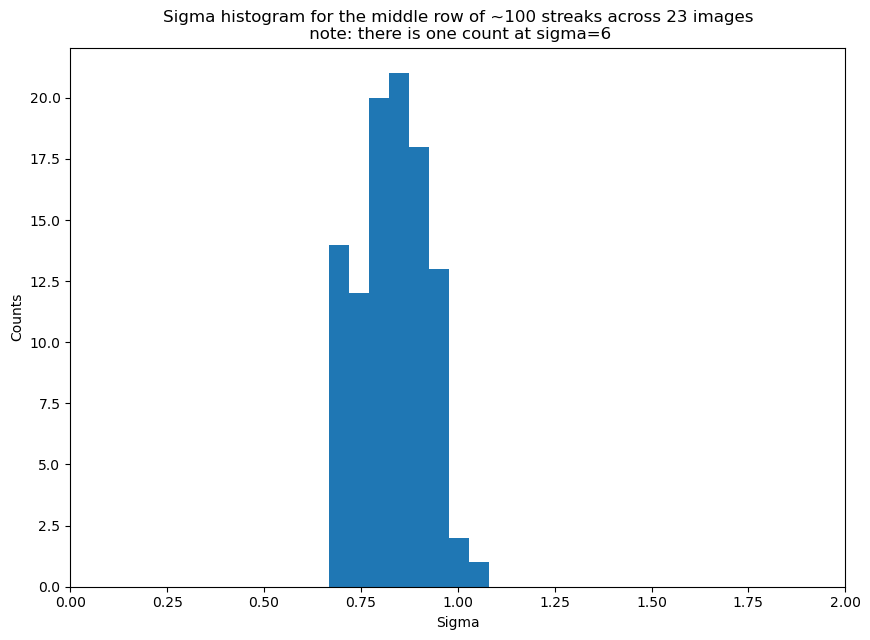

In [51]:
plt.hist(sigmas, bins=100)
plt.xlim(0, 2)
plt.title(
    "Sigma histogram for the middle row of ~100 streaks across 23 images\n note: there is one count at sigma=6"
)
plt.xlabel("Sigma")
plt.ylabel("Counts")
print("Average: ", np.average(sigmas))

In [30]:
sigmas_avg = []
for file in files:
    fpath = path + file
    f_list = get_widths(fpath, method="avg")
    for el in f_list:
        sigmas_avg.append(el)

Average:  0.9280296732568952


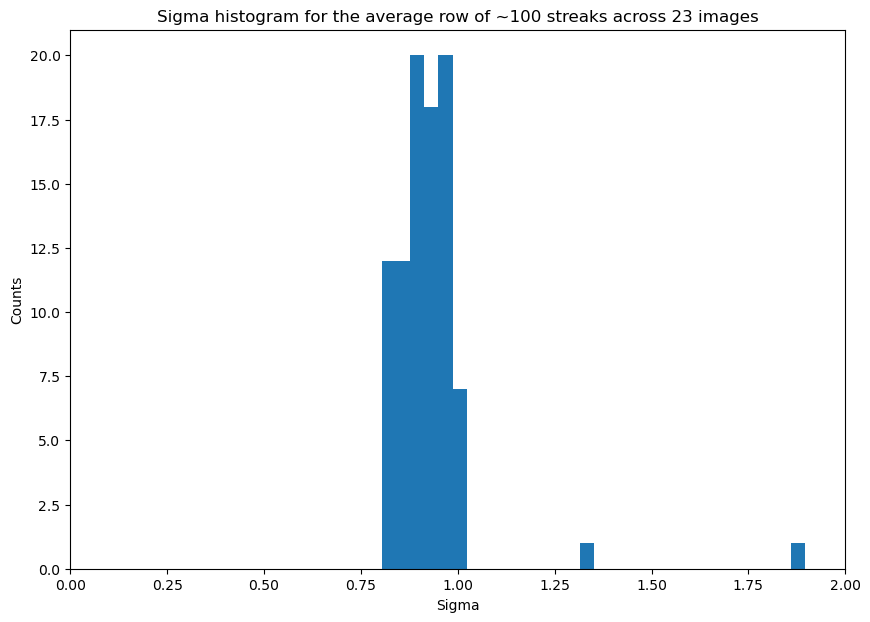

In [49]:
plt.hist(sigmas_avg, bins=30)
plt.xlim(0, 2)
plt.title("Sigma histogram for the average row of ~100 streaks across 23 images")
plt.xlabel("Sigma")
plt.ylabel("Counts")
print("Average: ", np.average(sigmas_avg))

In [39]:
sigmas_one = []
vals = np.linspace(50, 3000, 10)
file = "ztf_20221020154120_000640_zi_c05_x_0022.fits.fz"  # random
fpath = path + file

for val in vals:
    f_list = get_widths(fpath, method=int(val))
    for el in f_list:
        sigmas_one.append(el)

In [42]:
sigmas_one

[0.8755543017185086,
 0.8147957249837423,
 0.7350852342541603,
 0.6670073483933594,
 5.8921876415265535,
 0.7107799140018587,
 0.8326650361830892,
 0.8457879885837792,
 0.7474066748790591,
 1.6445567275085768,
 0.9383616131050488,
 0.9113622339605603,
 0.8057770108542779,
 0.8306867895556399,
 0.6905095149904563,
 0.8423255033091236,
 0.6788656499395195,
 0.8507568418740059,
 0.7525739375055802,
 1.8537806620273278,
 0.848524891560134,
 0.8316121343288451,
 0.7151575914293871,
 0.8965476590736506,
 1.5527610268959078,
 0.747901839927565,
 0.8720060019865036,
 0.7212198881579528,
 0.7718375195322136,
 1.4271528220078973,
 0.6771549443362085,
 0.8141397720701153,
 0.7610445305813115,
 0.8962738192594222,
 0.6053306917002542,
 1.6474390134339234,
 0.7177182867567857,
 0.8561102286833759,
 0.920501566533897,
 0.6772931109811288,
 0.731907625054698,
 0.7927206666912113,
 0.7722212407985837,
 0.8416521427121177,
 0.8044931933842182,
 0.7627059254354391,
 1.7847069320108335,
 0.82926042452912

Average:  0.9840626417575405


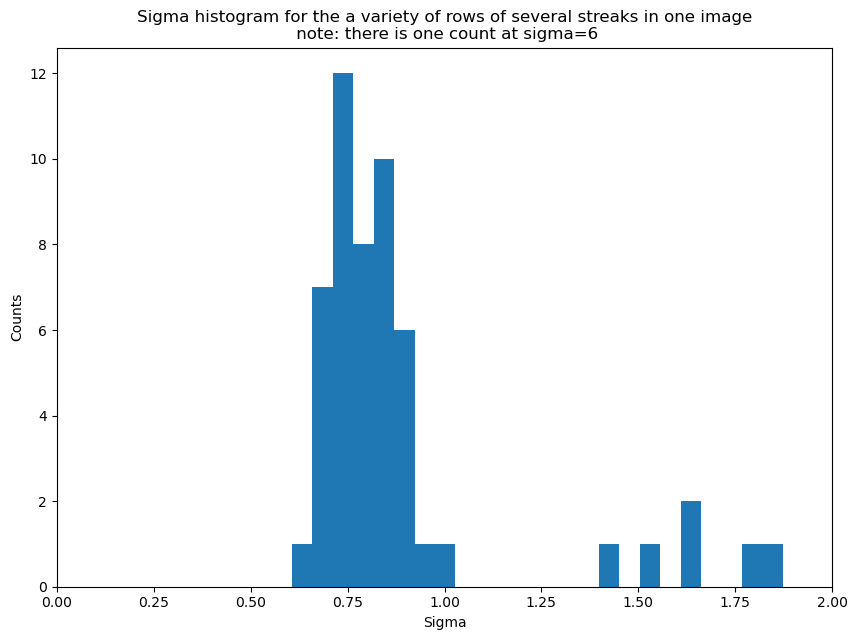

In [48]:
plt.hist(sigmas_one, bins=100)
plt.xlim(0, 2)
plt.title(
    "Sigma histogram for the a variety of rows of several streaks in one image\n note: there is one count at sigma=6"
)
plt.xlabel("Sigma")
plt.ylabel("Counts")
print("Average: ", np.average(sigmas_one))